In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score

In [14]:
TRAIN_IMAGE = 'train-images.idx3-ubyte'
TRAIN_LABEL = 'train-labels.idx1-ubyte'
TEST_IMAGE = 't10k-images.idx3-ubyte'
TEST_LABEL = 't10k-labels.idx1-ubyte'

def load_images(filepath):
    with open(filepath, 'rb') as f:
        # Bỏ qua 16 bytes header (Magic number, number of images, rows, cols)
        data = np.frombuffer(f.read(), dtype=np.uint8, offset=16)
    # Reshape về dạng (Số ảnh, 784 điểm ảnh)
    return data.reshape(-1, 28 * 28)

def load_labels(filepath):
    with open(filepath, 'rb') as f:
        # Bỏ qua 8 bytes header (Magic number, number of items)
        data = np.frombuffer(f.read(), dtype=np.uint8, offset=8)
    return data

X_train = load_images(TRAIN_IMAGE)/255.0 
y_train = load_labels(TRAIN_LABEL)
X_test = load_images(TEST_IMAGE)/255.0
y_test = load_labels(TEST_LABEL)

print(f"Kích thước tập Train (chỉ gồm 0 & 1): {X_train.shape}")
print(f"Kích thước tập Test  (chỉ gồm 0 & 1): {X_test.shape}\n")


Kích thước tập Train (chỉ gồm 0 & 1): (60000, 784)
Kích thước tập Test  (chỉ gồm 0 & 1): (10000, 784)



## Cài đặt softmax_regression bằng numpy

In [65]:
def softmax_stable(Z):
    e_Z = np.exp(Z - np.max(Z, axis=1, keepdims=True))
    A = e_Z / np.sum(e_Z, axis=1, keepdims=True)
    return A

def one_hot_encoding(y, n=10):
    m = len(y)
    tmp = np.zeros((m, n))  
    for i in range(m):
        tmp[i, y[i]] = 1    
    return tmp

def cross_entropy_loss(y_pred, y_onehot):
    n_samples = y_pred.shape[0]
    return -np.sum(y_onehot*np.log(y_pred + 1e-10))/n_samples

def learning_schedule(t, t0=5, t1=50):
    #Điều chỉnh giá trị learning rate theo từng epoch
    return t0/(t + t1)

class SoftmaxRegresstion:
    def  __init__(self, epochs=20, n_class=10):
        self.epochs = epochs
        self.n_class = n_class
        self.weights = None
        self.bias = None
        self.training_log = {
            "epoch": [],
            "loss": []
        }

    def train(self, X, y):
        n_samples, n_features = X.shape
        y_onehot = one_hot_encoding(y, self.n_class)

        #Nhân 0.01 loss giảm nhanh hơn
        self.weights = np.random.rand(n_features, self.n_class)*0.01  #784x10  
        #self.bias = np.random.rand(1, self.n_class)* 0.01 #1x10
        self.bias = np.zeros((1,self.n_class)) 

        # thuật toán SGD
        for epoch in range(self.epochs):
            for i in range(n_samples):
                random_index = np.random.randint(n_samples) 
                xi = X[random_index:random_index+1] #1 x 784
                yi = y_onehot[random_index:random_index+1] # 1 x10
                zi = xi @ self.weights + self.bias  # (1x784) @ (784x10) + (1x10) = (1x10)
                ai = softmax_stable(zi) #(1x10)
                ei = ai - yi #(1x10)
                gradient_w = xi.T @ ei #(784x10)
                gradient_b = ei

                alpha = learning_schedule(epoch * n_samples + i)

                self.weights -= alpha*gradient_w
                self.bias -= alpha*gradient_b
        
            Z = np.dot(X, self.weights) + self.bias
            A = softmax_stable(Z)
            #Tính Loss mỗi epoch
            loss = cross_entropy_loss(A, y_onehot)
            print(f"{epoch}     {loss}")
            self.training_log["epoch"].append(epoch)
            self.training_log["loss"].append(loss)

    def draw_loss(self):
        index = np.array(self.training_log["epoch"])
        loss = np.array(self.training_log["loss"])
        plt.figure(figsize=(6,4))
        plt.plot(index, loss)
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.tight_layout()
        plt.show()


    def predict(self, X):   
        Z = X @ self.weights + self.bias
        return np.argmax(softmax_stable(Z), axis=1)


In [66]:
rng = np.random.default_rng(36)
model = SoftmaxRegresstion(epochs=40, n_class=10)
model.train(X=X_train, y=y_train)

print("\nTest nhanh\nDự đoán:",model.predict(X_test[0]), "Đáp án: ",y_test[0])

0     0.4325909544891889
1     0.4225051427710226
2     0.41739223743803594
3     0.41396494459850064
4     0.4115007382546778
5     0.40949277488603936
6     0.40786970411511114
7     0.4065073991913267
8     0.4053233116992377
9     0.4043107789272589
10     0.40338077001937395
11     0.4025369427478803
12     0.4017995448155249
13     0.40112187112511566
14     0.4004965827535663
15     0.39990600834756296
16     0.39937583774449303
17     0.39887343174149903
18     0.39840013033482247
19     0.3979602727780659
20     0.39754165863782637
21     0.3971490140652403
22     0.3967748794194263
23     0.3964225153555199
24     0.3960850875919909
25     0.39575486901213397
26     0.39544701002490656
27     0.3951475230473305
28     0.39486620896813135
29     0.39458558313547704
30     0.3943209463306534
31     0.394069559445282
32     0.3938227192496442
33     0.3935838470130051
34     0.3933554314910096
35     0.39313669168674337
36     0.39291975155451403
37     0.39271028913441136
38   

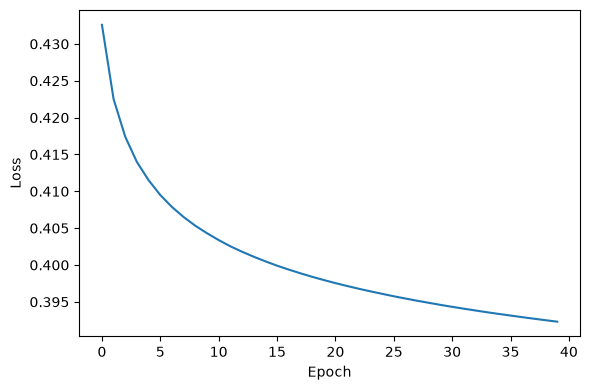

In [68]:
model.draw_loss()

In [74]:
def evaluate_metrics(y_true, y_pred, n_class=10):
    precisions = []
    recalls = []
    f1s = []

    for c in range(n_class):
        TP = np.sum((y_true == c) & (y_pred == c))
        FP = np.sum((y_true != c) & (y_pred == c))
        FN = np.sum((y_true == c) & (y_pred != c))

        precision_c = TP/(TP + FP) if (TP + FP) > 0 else 0.0
        recall_c = TP/(TP + FN) if (TP + FN) > 0 else 0.0
        f1_c = 2*(precision_c*recall_c)/(precision_c + recall_c) if (precision_c + recall_c) > 0 else 0.0

        precisions.append(precision_c)
        recalls.append(recall_c)
        f1s.append(f1_c)
    return {
        "Precision_macro": np.mean(precisions),
        "Recall_macro": np.mean(recalls),
        "F1_macro": np.mean(f1s),
    }

In [75]:
y_pred = model.predict(X_test)
eval = evaluate_metrics(y_true=y_test.astype(int), y_pred=y_pred)
print(f"Precision: {eval["Precision_macro"]:.4}")
print(f"Recall: {eval["Recall_macro"]:.4f}")
print(f"F1-macro: {eval["F1_macro"]:.4f}")

Precision: 0.8967
Recall: 0.8964
F1-macro: 0.8962


## Cài đặt softmax regression bằng thư viện scikit-learn

In [ ]:
skl_model = LogisticRegression(C=10,
                                max_iter=500, 
                                solver="lbfgs", 
                                random_state=36
                            )

skl_model.fit(X_train, y_train)

y_pred = skl_model.predict(X_test)

precision = precision_score(y_test, y_pred, average='macro')
recall = recall_score(y_test, y_pred, average='macro')
f1 = f1_score(y_test, y_pred, average='macro')

print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-macro  : {f1:.4f}")

Precision : 0.9238
Recall    : 0.9235
F1-Score  : 0.9236
